# 강판 표면 결함 유형 분류 - v3
XGB 클래스 가중치 · 배치 의존성 점검 · 2단계 모델/결정 가중치 · 5×5 반복 CV + 부트스트랩 CI

In [2]:
# ============================================================
# 강판(Steel Plates) 표면 결함 유형 분류 - v3
# ============================================================
# 데이터: steel_plates_faults.csv (1,941행 × 34열)
#
# 분할 (층화 추출, 60 / 20 / 20) - v2와 동일
#   - 학습(Train) / 검증(Validation) / 테스트(Test)
#   - 학습+검증(Dev)으로 반복 CV, 테스트는 마지막에 한 번만 평가
#
# v2 → v3 변경 사항
#   ① XGBoost 클래스 가중치
#      - sample_weight="balanced"를 자동으로 넣는 BalancedXGBClassifier 추가
#      - 가중치 없음 vs balanced를 5×5 반복 CV로 비교해 앙상블 후보 결정
#   ② 배치 의존성 점검 (변수 제거 실험)
#      - drop_basic : Length_of_Conveyer, Y_Minimum 제거
#      - drop_strict: + Y_Maximum(= Y_Minimum + Y_Range) 및
#                     Length_of_Conveyer로 만든 파생 변수 4개까지 제거
#      - 두 변수만으로 결함 유형을 맞히는 1-NN 진단도 함께 수행
#   ③ Bumps / Other_Faults / Pastry 구분
#      - 2단계 모델: 1단계 7분류 확률 중 세 유형 몫을
#                   세 유형 전용 분류기(2단계)가 다시 나눔
#      - 클래스별 결정 가중치(임계값) 조정: 교차 적합으로 효과를 정직하게 평가
#   ④ 비교 신뢰도
#      - 5-Fold 1회 → 5×5 반복 층화 CV (25개 폴드 점수)
#      - 모델 간 차이는 Nadeau-Bengio 보정 대응 t검정으로 신뢰구간·p값 산출
#      - 테스트 점수는 층화 부트스트랩 95% 신뢰구간 + 모델 간 대응 차이 구간
# ============================================================


# ============================================================
# 0. 라이브러리
# ============================================================

import itertools
import re
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

from scipy import stats
from scipy.stats import chi2_contingency, kruskal, randint, uniform

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    RandomizedSearchCV,
)
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    VotingClassifier,
)
from sklearn.inspection import permutation_importance
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

from lightgbm import LGBMClassifier, early_stopping
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 1. 기본 설정

In [3]:
# ============================================================
# 1. 기본 설정
# ============================================================

plt.rcParams["font.family"] = "Malgun Gothic"   # macOS: "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

RANDOM_STATE = 42
DATA_PATH = "steel_plates_faults.csv"
N_JOBS = -1

STEEL_COLS = ["TypeOfSteel_A300", "TypeOfSteel_A400"]

FAULT_COLS = [
    "Pastry",
    "Z_Scratch",
    "K_Scatch",
    "Stains",
    "Dirtiness",
    "Bumps",
    "Other_Faults",
]

TARGET = "Fault_Type"

class_mapping = {name: i for i, name in enumerate(FAULT_COLS)}
reverse_class_mapping = {i: name for name, i in class_mapping.items()}
LABELS = list(range(len(FAULT_COLS)))
N_CLASSES = len(LABELS)

STEEL_CODE = {"A300": 0, "A400": 1}

# --- v3 실험 설정 -------------------------------------------
N_SPLITS = 5                 # 반복 CV 폴드 수
N_REPEATS = 5                # 반복 횟수 (5×5 = 25개 폴드 점수)
N_BOOT = 2000                # 테스트 부트스트랩 반복 수
ALPHA = 0.05                 # 유의수준 (95% 구간)

# 서로 헷갈리는 세 유형 (2단계 모델·결정 가중치 조정 대상)
CONFUSABLE = ["Bumps", "Other_Faults", "Pastry"]
GROUP = [class_mapping[c] for c in CONFUSABLE]

# 변수 세트 결정 방식
#   "auto"       : 제거해도 유의하게 나빠지지 않으면 더 많이 제거한 세트를 사용
#   "full" / "drop_basic" / "drop_strict" : 강제 지정
FEATURE_POLICY = "auto"

# 클래스별 결정 가중치 적용 방식
#   "auto": 교차 적합 평가에서 평균 Macro F1이 오르면 적용 / "on" / "off"
CLASS_WEIGHT_POLICY = "auto"

# 1위와 통계적으로 구분되지 않는 후보 중 가장 단순한 모델을 고를지 여부
PREFER_SIMPLER = True

## 2. 데이터 불러오기 / 기본 확인

In [4]:
# ============================================================
# 2. 데이터 불러오기 / 기본 확인
# ============================================================

raw_df = pd.read_csv(DATA_PATH)

print("원본 데이터 크기:", raw_df.shape)
display(raw_df.head())

print("\n[결측치 합계]:", raw_df.isnull().sum().sum())
print("[중복 행 수]:", raw_df.duplicated().sum())

steel_sum = raw_df[STEEL_COLS].sum(axis=1)
fault_sum = raw_df[FAULT_COLS].sum(axis=1)

assert (steel_sum == 1).all(), "강종이 하나로 정해지지 않는 행이 있습니다."
assert (fault_sum == 1).all(), "결함 유형이 하나로 정해지지 않는 행이 있습니다."
print("원-핫 구조 확인 완료 (강종 / 결함 모두 행마다 정확히 1개)")

원본 데이터 크기: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0



[결측치 합계]: 0
[중복 행 수]: 0
원-핫 구조 확인 완료 (강종 / 결함 모두 행마다 정확히 1개)


## 3. 강종 / 결함 유형을 각각 한 열로 합치기

In [5]:
# ============================================================
# 3. 강종 / 결함 유형을 각각 한 열로 합치기
# ============================================================

def merge_columns(data: pd.DataFrame) -> pd.DataFrame:
    """강종 2열 → Steel_Type, 결함 7열 → Fault_Type"""

    out = data.copy()

    if set(STEEL_COLS).issubset(out.columns):
        position = out.columns.get_loc("TypeOfSteel_A300")
        steel_type = np.where(out["TypeOfSteel_A300"] == 1, "A300", "A400")
        out = out.drop(columns=STEEL_COLS)
        out.insert(position, "Steel_Type", steel_type)

    if set(FAULT_COLS).issubset(out.columns):
        out[TARGET] = out[FAULT_COLS].idxmax(axis=1)
        out = out.drop(columns=FAULT_COLS)

    return out


df = merge_columns(raw_df)
print("합친 후 데이터 크기:", df.shape)
df.to_csv("steel_plates_merged.csv", index=False)

합친 후 데이터 크기: (1941, 27)


## 4. 결함 유형 분포 / 강종 - 결함 유형 관계

In [6]:
# ============================================================
# 4. 결함 유형 분포 / 강종 - 결함 유형 관계
# ============================================================

class_counts = df[TARGET].value_counts().reindex(FAULT_COLS)
class_distribution = pd.DataFrame({
    "count": class_counts,
    "ratio(%)": (class_counts / len(df) * 100).round(2),
})
print("[결함 유형 분포]")
display(class_distribution)

steel_fault_table = pd.crosstab(df[TARGET], df["Steel_Type"]).reindex(FAULT_COLS)
chi2, p_value, dof, _ = chi2_contingency(steel_fault_table)
cramers_v = np.sqrt(chi2 / (len(df) * (min(steel_fault_table.shape) - 1)))

print("\n[결함 유형 × 강종 교차표]")
display(steel_fault_table)
print(f"Chi2 = {chi2:.2f}, 자유도 = {dof}, p-value = "
      f"{'<0.001' if p_value < 0.001 else round(p_value, 4)}, Cramér's V = {cramers_v:.3f}")

[결함 유형 분포]


,count,ratio(%)
Fault_Type,,
Pastry,158,8.14
Z_Scratch,190,9.79
K_Scatch,391,20.14
Stains,72,3.71
Dirtiness,55,2.83
Bumps,402,20.71
Other_Faults,673,34.67



[결함 유형 × 강종 교차표]


Steel_Type,A300,A400
Fault_Type,,
Pastry,49,109
Z_Scratch,172,18
K_Scatch,1,390
Stains,1,71
Dirtiness,9,46
Bumps,279,123
Other_Faults,266,407


Chi2 = 667.00, 자유도 = 6, p-value = <0.001, Cramér's V = 0.586


## 5. 모델 입력 변수 생성 (v2와 동일)

In [7]:
# ============================================================
# 5. 모델 입력 변수 생성 (v2와 동일)
# ============================================================

def build_features(data: pd.DataFrame) -> pd.DataFrame:

    out = data.drop(columns=[TARGET], errors="ignore").copy()
    out["Steel_Type"] = out["Steel_Type"].map(STEEL_CODE)

    if out["Steel_Type"].isnull().any():
        raise ValueError("Steel_Type에 A300 / A400 이외의 값이 있습니다.")

    out["X_Range"] = out["X_Maximum"] - out["X_Minimum"]
    out["Y_Range"] = out["Y_Maximum"] - out["Y_Minimum"]
    out["Aspect_Ratio"] = (out["X_Range"] + 1) / (out["Y_Range"] + 1)
    out["Luminosity_Range"] = out["Maximum_of_Luminosity"] - out["Minimum_of_Luminosity"]
    out["Mean_Luminosity"] = out["Sum_of_Luminosity"] / out["Pixels_Areas"]
    out["Perimeter_Area_Ratio"] = (out["X_Perimeter"] + out["Y_Perimeter"]) / out["Pixels_Areas"]

    conveyer = out["Length_of_Conveyer"]
    out["X_Min_Rel"] = out["X_Minimum"] / conveyer
    out["X_Max_Rel"] = out["X_Maximum"] / conveyer
    out["Edge_Dist"] = np.minimum(out["X_Minimum"], conveyer - out["X_Maximum"]).clip(lower=0)
    out["Edge_Dist_Rel"] = out["Edge_Dist"] / conveyer
    out["Lum_Contrast"] = out["Luminosity_Range"] / (out["Mean_Luminosity"] + 1)
    out["Thick_x_Steel"] = out["Steel_Plate_Thickness"] * (1 + out["Steel_Type"])

    return out


X_all = build_features(df)
y_all = df[TARGET].map(class_mapping)
feature_cols = X_all.columns.tolist()
print("입력 변수 수:", len(feature_cols))

SKEWED_COLS = [
    "Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity",
    "X_Range", "Y_Range", "Aspect_Ratio", "Perimeter_Area_Ratio", "Edge_Dist",
]

# ------------------------------------------------------------
# [v3] 배치 의존성 점검용 변수 세트
# ------------------------------------------------------------
# - Length_of_Conveyer: 강판(배치)마다 거의 고정된 값 → 배치 식별자 역할 가능
# - Y_Minimum         : 코일 길이 방향 위치. 같은 강판의 결함끼리 값이 가까움
# - Y_Maximum         : Y_Minimum + Y_Range 이므로 Y_Minimum만 빼면 정보가 그대로 남음
# - X_Min_Rel, X_Max_Rel, Edge_Dist, Edge_Dist_Rel: Length_of_Conveyer로 계산
# ------------------------------------------------------------
BATCH_BASIC = ["Length_of_Conveyer", "Y_Minimum"]
BATCH_STRICT = BATCH_BASIC + [
    "Y_Maximum", "X_Min_Rel", "X_Max_Rel", "Edge_Dist", "Edge_Dist_Rel",
]

FEATURE_SETS = {
    "full": feature_cols,
    "drop_basic": [c for c in feature_cols if c not in BATCH_BASIC],
    "drop_strict": [c for c in feature_cols if c not in BATCH_STRICT],
}
for k, v in FEATURE_SETS.items():
    print(f"  {k:<12}: {len(v)}개 변수")

입력 변수 수: 38
  full        : 38개 변수
  drop_basic  : 36개 변수
  drop_strict : 31개 변수


## 6. 수치 변수 - 결함 유형 연관성 (Kruskal-Wallis ε²)

In [8]:
# ============================================================
# 6. 수치 변수 - 결함 유형 연관성 (Kruskal-Wallis ε²)
# ============================================================

n_obs = len(df)
kw_results = []
for col in feature_cols:
    if col == "Steel_Type":
        continue
    h_stat, p_val = kruskal(*[X_all.loc[y_all == k, col] for k in LABELS])
    kw_results.append({
        "Feature": col,
        "H": h_stat,
        "Epsilon²": max(0.0, (h_stat - N_CLASSES + 1) / (n_obs - N_CLASSES)),
    })

kw_df = pd.DataFrame(kw_results).sort_values("Epsilon²", ascending=False).reset_index(drop=True)
display(kw_df.head(15).round(4))

,Feature,H,Epsilon²
0,Perimeter_Area_Ratio,849.7964,0.4363
1,Sum_of_Luminosity,827.9525,0.4250
2,Outside_X_Index,821.6631,0.4217
3,Log_X_Index,809.4836,0.4155
4,X_Range,809.4836,0.4155
5,LogOfAreas,786.3354,0.4035
6,Pixels_Areas,786.3354,0.4035
7,Y_Perimeter,736.9414,0.3779
8,X_Perimeter,734.4772,0.3767
9,Edges_Y_Index,715.2621,0.3667


## 7. 학습 / 검증 / 테스트 분할 (60 / 20 / 20, 층화) - v2와 동일

In [9]:
# ============================================================
# 7. 학습 / 검증 / 테스트 분할 (60 / 20 / 20, 층화) - v2와 동일
# ============================================================

X_temp, X_test, y_temp, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE,
)

X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
y_dev_np = y_dev.to_numpy()
y_test_np = y_test.to_numpy()

print(f"학습 {len(X_train)} / 검증 {len(X_val)} / 테스트 {len(X_test)} "
      f"(Dev = {len(X_dev)})")

split_info = pd.Series("train", index=X_all.index)
split_info[X_val.index] = "val"
split_info[X_test.index] = "test"
df.assign(Split=split_info).to_csv("data_split_info.csv", index_label="row_id")

학습 1164 / 검증 388 / 테스트 389 (Dev = 1552)


## 8. 모델 정의

In [10]:
# ============================================================
# 8. 모델 정의
# ============================================================

def make_lr(cols):
    skewed = [c for c in SKEWED_COLS if c in cols]
    other = [c for c in cols if c not in skewed]
    preprocessor = ColumnTransformer([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"), skewed),
        ("pass", "passthrough", other),
    ])
    return Pipeline([
        ("preprocess", preprocessor),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=10.0, class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE,
        )),
    ])


def make_rf():
    return RandomForestClassifier(
        n_estimators=300, max_depth=20, max_features=0.3,
        min_samples_split=9, min_samples_leaf=1,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE, n_jobs=N_JOBS,
    )


ET_BASE_PARAMS = dict(
    n_estimators=500, max_features=0.5, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
)


def make_et(**params):
    return ExtraTreesClassifier(**{**ET_BASE_PARAMS, **params})


LGBM_PARAMS = dict(
    objective="multiclass", learning_rate=0.05, num_leaves=22,
    min_child_samples=30, subsample=0.7, subsample_freq=1,
    colsample_bytree=0.65, class_weight="balanced",
    random_state=RANDOM_STATE, n_jobs=N_JOBS, verbose=-1,
)

XGB_PARAMS = dict(
    learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.7,
    random_state=RANDOM_STATE, n_jobs=N_JOBS,
)


class BalancedXGBClassifier(XGBClassifier):
    """
    [v3] fit 시 sample_weight가 주어지지 않으면 클래스 균형 가중치를 자동 계산.
    LGBM / RF / ET의 class_weight="balanced"와 같은 조건으로 맞추기 위한 래퍼.
    CV, VotingClassifier, permutation_importance 안에서도 그대로 동작한다.
    """

    def fit(self, X, y, *, sample_weight=None, **kwargs):
        if sample_weight is None:
            sample_weight = compute_sample_weight("balanced", y)
        return super().fit(X, y, sample_weight=sample_weight, **kwargs)


# 부스팅 트리 수: 9단계 조기 종료 결과를 넣어 사용 (변수 세트가 바뀌면 다시 계산)
N_TREES = {}


def make_lgbm(n_trees=None):
    return LGBMClassifier(n_estimators=n_trees or N_TREES["lgbm"], **LGBM_PARAMS)


def make_xgb(n_trees=None):
    return XGBClassifier(n_estimators=n_trees or N_TREES["xgb"], **XGB_PARAMS)


def make_xgb_bal(n_trees=None):
    return BalancedXGBClassifier(n_estimators=n_trees or N_TREES["xgb_bal"], **XGB_PARAMS)


# ------------------------------------------------------------
# 2단계 모델 / 결정 가중치 래퍼
# ------------------------------------------------------------

def _take_rows(X, mask):
    return X.iloc[np.flatnonzero(mask)] if hasattr(X, "iloc") else X[mask]


def mix_two_stage(base_proba, spec_proba, group=GROUP):
    """
    1단계 확률에서 세 유형(group)의 확률 합을 구하고,
    그 몫을 2단계 전용 분류기 확률대로 다시 나눈다.
    나머지 4개 유형의 확률은 그대로 두므로 전체 합은 1로 유지된다.
    """
    out = np.array(base_proba, dtype=float, copy=True)
    mass = out[..., group].sum(axis=-1, keepdims=True)
    out[..., group] = mass * spec_proba
    return out


class TwoStageClassifier(ClassifierMixin, BaseEstimator):
    """1단계: 7분류 / 2단계: group 유형만으로 학습한 전용 분류기"""

    def __init__(self, base=None, specialist=None, group=tuple(GROUP)):
        self.base = base
        self.specialist = specialist
        self.group = group

    def fit(self, X, y):
        y = np.asarray(y)
        group = list(self.group)

        self.base_ = clone(self.base).fit(X, y)
        self.classes_ = self.base_.classes_

        mask = np.isin(y, group)
        local = {lab: i for i, lab in enumerate(group)}
        y_sub = np.array([local[v] for v in y[mask]])
        self.specialist_ = clone(self.specialist).fit(_take_rows(X, mask), y_sub)

        self.group_idx_ = [list(self.classes_).index(g) for g in group]
        return self

    def predict_proba(self, X):
        return mix_two_stage(
            self.base_.predict_proba(X),
            self.specialist_.predict_proba(X),
            group=self.group_idx_,
        )

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class ClassWeightedClassifier(ClassifierMixin, BaseEstimator):
    """
    확률에 클래스별 가중치를 곱한 뒤 argmax로 결정 (= 클래스별 임계값 조정).
    predict_proba는 원래 확률을 그대로 돌려주고, predict만 가중치를 반영한다.
    """

    def __init__(self, estimator=None, class_weights=None):
        self.estimator = estimator
        self.class_weights = class_weights

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator).fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

    def predict(self, X):
        w = np.ones(len(self.classes_)) if self.class_weights is None else np.asarray(self.class_weights)
        return self.classes_[(self.predict_proba(X) * w).argmax(axis=1)]

## 9. 평가 도구: 반복 CV / 보정 t검정 / 부스팅 조기 종료

In [11]:
# ============================================================
# 9. 평가 도구: 반복 CV / 보정 t검정 / 부스팅 조기 종료
# ============================================================

rcv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=RANDOM_STATE,
)
SPLITS = list(rcv.split(X_dev, y_dev))          # 반복 r의 폴드 f → SPLITS[r * N_SPLITS + f]
N_FOLDS_TOTAL = len(SPLITS)
TEST_TRAIN_RATIO = 1 / (N_SPLITS - 1)           # 보정 t검정용 n_test / n_train


def decide(proba, weights=None):
    """확률 → 예측 라벨 (가중치가 있으면 곱한 뒤 argmax). 마지막 축 기준."""
    return (proba if weights is None else proba * weights).argmax(axis=-1)


def oof_predict(make_model, cols, labels_subset=None):
    """
    반복 CV의 OOF 확률 (N_REPEATS, n_dev, n_class).
    labels_subset을 주면 해당 유형 행만으로 학습한 전용 분류기의 확률을
    모든 검증 행에 대해 구한다 (2단계 모델용).
    """
    n_out = N_CLASSES if labels_subset is None else len(labels_subset)
    oof = np.full((N_REPEATS, len(X_dev), n_out), np.nan)
    X_cols = X_dev[cols]

    for i, (tr, va) in enumerate(SPLITS):
        X_tr, y_tr = X_cols.iloc[tr], y_dev_np[tr]

        if labels_subset is not None:
            mask = np.isin(y_tr, labels_subset)
            local = {lab: j for j, lab in enumerate(labels_subset)}
            X_tr = X_tr.iloc[np.flatnonzero(mask)]
            y_tr = np.array([local[v] for v in y_tr[mask]])

        model = make_model().fit(X_tr, y_tr)
        oof[i // N_SPLITS, va] = model.predict_proba(X_cols.iloc[va])

    return oof


def fold_scores(pred):
    """예측 라벨 (N_REPEATS, n_dev) → 25개 폴드별 Macro F1"""
    return np.array([
        f1_score(y_dev_np[va], pred[i // N_SPLITS, va], average="macro", zero_division=0)
        for i, (_, va) in enumerate(SPLITS)
    ])


def per_class_prf(pred):
    """반복별 OOF 전체에 대한 클래스별 precision / recall / F1 (반복 평균)"""
    stats_ = np.array([
        precision_recall_fscore_support(
            y_dev_np, pred[r], labels=LABELS, zero_division=0
        )[:3]
        for r in range(pred.shape[0])
    ]).mean(axis=0)
    return pd.DataFrame(stats_.T, index=FAULT_COLS, columns=["precision", "recall", "f1"])


def corrected_ttest(scores_a, scores_b):
    """
    Nadeau & Bengio(2003) 보정 대응 t검정.
    반복 CV 폴드 점수는 학습 데이터가 겹쳐 서로 독립이 아니므로
    분산에 (1/k + n_test/n_train)을 곱해 과도한 유의 판정을 막는다.
    반환: 평균 차이(a - b), 95% 신뢰구간, p값
    """
    d = np.asarray(scores_a) - np.asarray(scores_b)
    k = len(d)
    var = d.var(ddof=1)
    if var == 0:
        return d.mean(), d.mean(), d.mean(), 1.0
    se = np.sqrt((1 / k + TEST_TRAIN_RATIO) * var)
    t_stat = d.mean() / se
    p = 2 * stats.t.sf(abs(t_stat), df=k - 1)
    half = stats.t.ppf(1 - ALPHA / 2, df=k - 1) * se
    return d.mean(), d.mean() - half, d.mean() + half, p


def find_n_trees(cols, return_curves=False):
    """학습 → 검증 조기 종료로 LGBM / XGB / XGB(balanced) 트리 수 결정"""

    Xtr, Xva = X_train[cols], X_val[cols]

    lgbm_es = LGBMClassifier(n_estimators=3000, **LGBM_PARAMS).fit(
        Xtr, y_train, eval_set=[(Xva, y_val)], eval_metric="multi_logloss",
        callbacks=[early_stopping(stopping_rounds=50, verbose=False)],
    )

    xgb_es = XGBClassifier(
        n_estimators=3000, eval_metric="mlogloss", early_stopping_rounds=50, **XGB_PARAMS,
    ).fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=False)

    # balanced: 학습·검증 손실 모두 같은 균형 가중치로 계산
    xgb_bal_es = XGBClassifier(
        n_estimators=3000, eval_metric="mlogloss", early_stopping_rounds=50, **XGB_PARAMS,
    ).fit(
        Xtr, y_train,
        sample_weight=compute_sample_weight("balanced", y_train),
        eval_set=[(Xva, y_val)],
        sample_weight_eval_set=[compute_sample_weight("balanced", y_val)],
        verbose=False,
    )

    trees = {
        "lgbm": int(lgbm_es.best_iteration_),
        "xgb": int(xgb_es.best_iteration) + 1,
        "xgb_bal": int(xgb_bal_es.best_iteration) + 1,
    }
    if not return_curves:
        return trees

    curves = {
        "LightGBM": lgbm_es.evals_result_["valid_0"]["multi_logloss"],
        "XGBoost": xgb_es.evals_result()["validation_0"]["mlogloss"],
        "XGBoost (balanced)": xgb_bal_es.evals_result()["validation_0"]["mlogloss"],
    }
    return trees, curves


print(f"반복 층화 CV: {N_SPLITS}-Fold × {N_REPEATS}회 = {N_FOLDS_TOTAL}개 폴드 점수")

반복 층화 CV: 5-Fold × 5회 = 25개 폴드 점수


## 10. 부스팅 트리 수 결정 (전체 변수, 학습 → 검증 조기 종료)

트리 수 (전체 변수): {'lgbm': 103, 'xgb': 186, 'xgb_bal': 130}


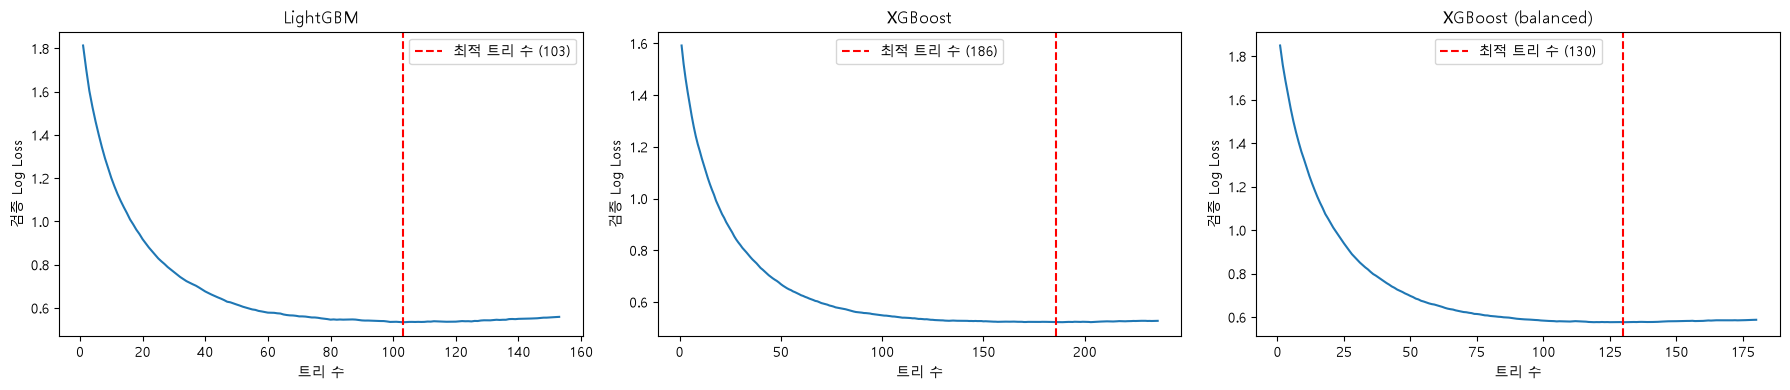

In [12]:
# ============================================================
# 10. 부스팅 트리 수 결정 (전체 변수, 학습 → 검증 조기 종료)
# ============================================================

TREES_FULL, es_curves = find_n_trees(FEATURE_SETS["full"], return_curves=True)
N_TREES = dict(TREES_FULL)
print("트리 수 (전체 변수):", TREES_FULL)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (title, curve), key in zip(axes, es_curves.items(), ["lgbm", "xgb", "xgb_bal"]):
    ax.plot(range(1, len(curve) + 1), curve)
    ax.axvline(TREES_FULL[key], color="red", linestyle="--",
               label=f"최적 트리 수 ({TREES_FULL[key]})")
    ax.set_xlabel("트리 수")
    ax.set_ylabel("검증 Log Loss")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

## 11. [개선 ②] XGBoost 클래스 가중치 비교 (5×5 반복 CV)

In [13]:
# ============================================================
# 11. [개선 ②] XGBoost 클래스 가중치 비교 (5×5 반복 CV)
# ============================================================
# 같은 분할(SPLITS)에서 가중치 없음 / balanced를 학습해 대응 비교한다.
# 결정 규칙: 가중치 없는 쪽이 "유의하게" 좋지 않으면 balanced 사용
#           (다른 트리 모델과 조건을 맞추는 것이 기본값)
# ============================================================

print("=" * 60)
print("XGBoost: 가중치 없음 vs balanced (전체 변수)")
print("=" * 60)

FULL = FEATURE_SETS["full"]
start = time.time()
oof_xgb_full = oof_predict(make_xgb, FULL)
oof_xgb_bal_full = oof_predict(make_xgb_bal, FULL)
print(f"소요 시간: {time.time() - start:.1f}초")

s_plain = fold_scores(decide(oof_xgb_full))
s_bal = fold_scores(decide(oof_xgb_bal_full))
xgb_diff, xgb_lo, xgb_hi, xgb_p = corrected_ttest(s_bal, s_plain)

print(f"XGBoost            Macro F1 = {s_plain.mean():.4f} ± {s_plain.std():.4f}")
print(f"XGBoost (balanced) Macro F1 = {s_bal.mean():.4f} ± {s_bal.std():.4f}")
print(f"차이(balanced - 없음) = {xgb_diff:+.4f}  95% CI [{xgb_lo:+.4f}, {xgb_hi:+.4f}]  p = {xgb_p:.3f}")

xgb_class_cmp = pd.concat({
    "XGB": per_class_prf(decide(oof_xgb_full)),
    "XGB_bal": per_class_prf(decide(oof_xgb_bal_full)),
}, axis=1)
xgb_class_cmp[("Δ", "recall")] = xgb_class_cmp[("XGB_bal", "recall")] - xgb_class_cmp[("XGB", "recall")]
xgb_class_cmp[("Δ", "precision")] = xgb_class_cmp[("XGB_bal", "precision")] - xgb_class_cmp[("XGB", "precision")]
print("\n[클래스별 비교 (OOF, 반복 평균)]")
display(xgb_class_cmp.round(4))

if xgb_hi < 0:
    XGB_POOL = "XGBoost"
    print("→ 가중치 없는 XGBoost가 유의하게 우수: 앙상블 후보에 가중치 없는 버전 사용")
else:
    XGB_POOL = "XGBoost (balanced)"
    print("→ balanced가 같거나 우수: 앙상블 후보에 balanced 버전 사용")

xgb_weight_result = pd.DataFrame([{
    "XGB F1": s_plain.mean(), "XGB_bal F1": s_bal.mean(),
    "Diff": xgb_diff, "CI low": xgb_lo, "CI high": xgb_hi, "p": xgb_p, "Chosen": XGB_POOL,
}])

XGBoost: 가중치 없음 vs balanced (전체 변수)
소요 시간: 40.8초
XGBoost            Macro F1 = 0.8180 ± 0.0195
XGBoost (balanced) Macro F1 = 0.8124 ± 0.0192
차이(balanced - 없음) = -0.0056  95% CI [-0.0241, +0.0130]  p = 0.540

[클래스별 비교 (OOF, 반복 평균)]


XGB                   XGB_bal                       Δ          
             precision  recall      f1 precision  recall      f1  recall precision
Pastry          0.6941  0.5651  0.6228    0.6119  0.6825  0.6449  0.1175   -0.0822
Z_Scratch       0.9525  0.9211  0.9365    0.9254  0.9303  0.9278  0.0092   -0.0271
K_Scatch        0.9733  0.9534  0.9632    0.9650  0.9521  0.9585 -0.0013   -0.0082
Stains          0.9402  0.9172  0.9285    0.8962  0.9207  0.9082  0.0034   -0.0440
Dirtiness       0.9495  0.7727  0.8520    0.8653  0.8136  0.8385  0.0409   -0.0842
Bumps           0.6859  0.6698  0.6776    0.6497  0.7346  0.6894  0.0648   -0.0362
Other_Faults    0.7223  0.7918  0.7554    0.7642  0.6896  0.7249 -0.1022    0.0419

→ balanced가 같거나 우수: 앙상블 후보에 balanced 버전 사용


## 12. [개선 ③] 배치 의존성 점검 - 변수 제거 실험 (5×5 반복 CV)

(a) 배치 식별 진단: Length_of_Conveyer + Y_Minimum 두 변수만 사용


,Model (2개 변수만),Macro F1,SD,Accuracy
0,1-NN (표준화),0.4069,0.0219,0.4879
1,ExtraTrees,0.4372,0.0337,0.5240


(참고) 최빈 클래스만 예측할 때 Macro F1 = 0.0735
→ 위치·컨베이어 길이만으로 점수가 높게 나오면, 같은 강판의 결함들이 학습·검증에 섞여 '배치 기억'이 가능하다는 뜻입니다.

(b) 변수 제거 실험
full         완료 (26.9초), 트리 수 {'lgbm': 103, 'xgb': 186, 'xgb_bal': 130}
drop_basic   완료 (40.9초), 트리 수 {'lgbm': 110, 'xgb': 173, 'xgb_bal': 133}
drop_strict  완료 (38.5초), 트리 수 {'lgbm': 110, 'xgb': 176, 'xgb_bal': 132}

[변수 제거 실험 결과 - Δ는 full 대비, 보정 t검정 95% CI]


,Model,Feature set,n_features,CV Macro F1,SD,Δ vs full,CI low,CI high,p
0,ExtraTrees,full,38,0.8151,0.0209,0.0000,0.0000,0.0000,1.0000
1,ExtraTrees,drop_basic,36,0.7920,0.0225,-0.0231,-0.0365,-0.0096,0.0017
2,ExtraTrees,drop_strict,31,0.7787,0.0269,-0.0364,-0.0545,-0.0182,0.0004
3,LightGBM,full,38,0.8127,0.0183,0.0000,0.0000,0.0000,1.0000
4,LightGBM,drop_basic,36,0.7919,0.0189,-0.0208,-0.0339,-0.0076,0.0034
5,LightGBM,drop_strict,31,0.7889,0.0196,-0.0238,-0.0376,-0.0100,0.0016
6,XGBoost (balanced),full,38,0.8124,0.0192,0.0000,0.0000,0.0000,1.0000
7,XGBoost (balanced),drop_basic,36,0.7931,0.0190,-0.0193,-0.0350,-0.0037,0.0175
8,XGBoost (balanced),drop_strict,31,0.7891,0.0206,-0.0234,-0.0413,-0.0055,0.0126
9,평균 앙상블,full,38,0.8235,0.0199,0.0000,0.0000,0.0000,1.0000



[평균 앙상블 - 클래스별 F1 변화]


,full,drop_basic,drop_strict,Δ basic,Δ strict
Pastry,0.6497,0.6186,0.6081,-0.0311,-0.0416
Z_Scratch,0.9311,0.8896,0.8885,-0.0415,-0.0427
K_Scatch,0.9636,0.9585,0.9553,-0.0051,-0.0084
Stains,0.9179,0.9128,0.9140,-0.0050,-0.0039
Dirtiness,0.8755,0.8681,0.8200,-0.0074,-0.0555
Bumps,0.6935,0.6792,0.6663,-0.0143,-0.0272
Other_Faults,0.7383,0.7164,0.7089,-0.0219,-0.0294


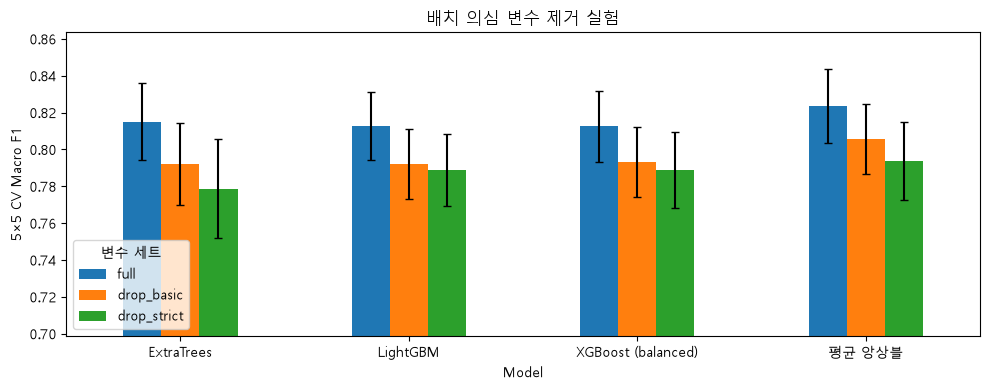

drop_basic  : Δ = -0.0180 [-0.0311, -0.0049] → 유의한 하락 → 해당 변수에 의존 (배치 정보 의존 가능성)
drop_strict : Δ = -0.0297 [-0.0491, -0.0103] → 유의한 하락 → 해당 변수에 의존 (배치 정보 의존 가능성)
※ 제거 시 성능이 유의하게 떨어집니다. 전체 변수를 유지하지만, 새 강판(배치)에 대한 실제 성능은 CV보다 낮을 수 있습니다.

→ 이후 사용할 변수 세트: full (38개)


In [14]:
# ============================================================
# 12. [개선 ③] 배치 의존성 점검 - 변수 제거 실험 (5×5 반복 CV)
# ============================================================
# 무작위 분할에서는 같은 강판(배치)의 결함이 학습·검증 양쪽에 들어간다.
# Length_of_Conveyer / Y_Minimum이 "어느 강판인가"를 알려주는 역할을 한다면
# CV 점수가 부풀려지고, 이 변수를 빼면 점수가 크게 떨어진다.
#
# (a) 진단: 두 변수만으로 1-NN 분류 → 높으면 배치 식별 가능성
# (b) 제거 실험: full / drop_basic / drop_strict, 참조 모델 3종 + 평균 앙상블
#     변수 세트마다 부스팅 트리 수를 다시 조기 종료로 정한다.
# ============================================================

print("=" * 60)
print("(a) 배치 식별 진단: Length_of_Conveyer + Y_Minimum 두 변수만 사용")
print("=" * 60)

diag_rows = []
for name, maker in {
    "1-NN (표준화)": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
    "ExtraTrees": lambda: make_et(n_estimators=300),
}.items():
    pred = decide(oof_predict(maker, BATCH_BASIC))
    sc = fold_scores(pred)
    diag_rows.append({"Model (2개 변수만)": name, "Macro F1": sc.mean(), "SD": sc.std(),
                      "Accuracy": np.mean([accuracy_score(y_dev_np, pred[r]) for r in range(N_REPEATS)])})

majority_f1 = f1_score(y_dev_np, np.full_like(y_dev_np, y_dev.mode()[0]), average="macro")
batch_diag_df = pd.DataFrame(diag_rows)
display(batch_diag_df.round(4))
print(f"(참고) 최빈 클래스만 예측할 때 Macro F1 = {majority_f1:.4f}")
print("→ 위치·컨베이어 길이만으로 점수가 높게 나오면, 같은 강판의 결함들이 "
      "학습·검증에 섞여 '배치 기억'이 가능하다는 뜻입니다.")


print("\n" + "=" * 60)
print("(b) 변수 제거 실험")
print("=" * 60)

ABLATION_MODELS = ["ExtraTrees", "LightGBM", XGB_POOL]
ablation_oof, ablation_trees = {}, {}

for fs_name, cols in FEATURE_SETS.items():

    start = time.time()
    trees = TREES_FULL if fs_name == "full" else find_n_trees(cols)
    ablation_trees[fs_name] = trees

    makers = {
        "ExtraTrees": lambda: make_et(),
        "LightGBM": lambda t=trees: make_lgbm(t["lgbm"]),
        "XGBoost": lambda t=trees: make_xgb(t["xgb"]),
        "XGBoost (balanced)": lambda t=trees: make_xgb_bal(t["xgb_bal"]),
    }

    for m in ABLATION_MODELS:
        if fs_name == "full" and m == "XGBoost (balanced)":
            ablation_oof[(fs_name, m)] = oof_xgb_bal_full
        elif fs_name == "full" and m == "XGBoost":
            ablation_oof[(fs_name, m)] = oof_xgb_full
        else:
            ablation_oof[(fs_name, m)] = oof_predict(makers[m], cols)

    ablation_oof[(fs_name, "평균 앙상블")] = np.mean(
        [ablation_oof[(fs_name, m)] for m in ABLATION_MODELS], axis=0
    )
    print(f"{fs_name:<12} 완료 ({time.time() - start:.1f}초), 트리 수 {trees}")

ablation_rows = []
for m in ABLATION_MODELS + ["평균 앙상블"]:
    base_scores = fold_scores(decide(ablation_oof[("full", m)]))
    for fs_name in FEATURE_SETS:
        sc = fold_scores(decide(ablation_oof[(fs_name, m)]))
        d, l, h, p = corrected_ttest(sc, base_scores) if fs_name != "full" else (0, 0, 0, 1)
        ablation_rows.append({
            "Model": m, "Feature set": fs_name, "n_features": len(FEATURE_SETS[fs_name]),
            "CV Macro F1": sc.mean(), "SD": sc.std(),
            "Δ vs full": d, "CI low": l, "CI high": h, "p": p,
        })

ablation_df = pd.DataFrame(ablation_rows)
print("\n[변수 제거 실험 결과 - Δ는 full 대비, 보정 t검정 95% CI]")
display(ablation_df.round(4))

ens_class = pd.concat({
    fs: per_class_prf(decide(ablation_oof[(fs, "평균 앙상블")]))["f1"] for fs in FEATURE_SETS
}, axis=1)
ens_class["Δ basic"] = ens_class["drop_basic"] - ens_class["full"]
ens_class["Δ strict"] = ens_class["drop_strict"] - ens_class["full"]
print("\n[평균 앙상블 - 클래스별 F1 변화]")
display(ens_class.round(4))

pivot = ablation_df.pivot(index="Model", columns="Feature set", values="CV Macro F1")[list(FEATURE_SETS)]
err = ablation_df.pivot(index="Model", columns="Feature set", values="SD")[list(FEATURE_SETS)]
pivot.plot(kind="bar", yerr=err, figsize=(10, 4), capsize=3)
plt.ylabel("5×5 CV Macro F1")
plt.title("배치 의심 변수 제거 실험")
plt.ylim(max(0, pivot.min().min() - 0.08), min(1, pivot.max().max() + 0.04))
plt.xticks(rotation=0)
plt.legend(title="변수 세트")
plt.tight_layout()
plt.show()

# 해석 및 변수 세트 결정 (참조: 평균 앙상블)
ens_res = ablation_df[ablation_df["Model"] == "평균 앙상블"].set_index("Feature set")


def significantly_worse(fs):
    return ens_res.loc[fs, "CI high"] < 0


for fs in ["drop_basic", "drop_strict"]:
    r = ens_res.loc[fs]
    verdict = ("유의한 하락 → 해당 변수에 의존 (배치 정보 의존 가능성)"
               if significantly_worse(fs) else "유의한 차이 없음 → 의존도 낮음")
    print(f"{fs:<12}: Δ = {r['Δ vs full']:+.4f} [{r['CI low']:+.4f}, {r['CI high']:+.4f}] → {verdict}")

if FEATURE_POLICY == "auto":
    if not significantly_worse("drop_strict"):
        FEATURE_SET_NAME = "drop_strict"
    elif not significantly_worse("drop_basic"):
        FEATURE_SET_NAME = "drop_basic"
    else:
        FEATURE_SET_NAME = "full"
        print("※ 제거 시 성능이 유의하게 떨어집니다. 전체 변수를 유지하지만, "
              "새 강판(배치)에 대한 실제 성능은 CV보다 낮을 수 있습니다.")
else:
    FEATURE_SET_NAME = FEATURE_POLICY

FEATURES = FEATURE_SETS[FEATURE_SET_NAME]
print(f"\n→ 이후 사용할 변수 세트: {FEATURE_SET_NAME} ({len(FEATURES)}개)")

## 13. 선택된 변수 세트로 트리 수 재설정 + ExtraTrees 탐색

In [15]:
# ============================================================
# 13. 선택된 변수 세트로 트리 수 재설정 + ExtraTrees 탐색
# ============================================================

N_TREES = dict(ablation_trees[FEATURE_SET_NAME])
print("트리 수:", N_TREES)

ET_SEARCH_ITER = 15
start = time.time()
et_search = RandomizedSearchCV(
    estimator=make_et(),
    param_distributions={
        "n_estimators": randint(300, 1000),
        "max_features": uniform(0.2, 0.6),
        "min_samples_split": randint(2, 8),
        "min_samples_leaf": randint(1, 3),
        "max_depth": [None, 20, 30],
    },
    n_iter=ET_SEARCH_ITER,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1,
    random_state=RANDOM_STATE,
    refit=False,
)
et_search.fit(X_dev[FEATURES], y_dev)

ET_BEST_PARAMS = {k: (v.item() if hasattr(v, "item") else v)
                  for k, v in et_search.best_params_.items()}
print(f"ExtraTrees 탐색 {time.time() - start:.1f}초, CV F1 {et_search.best_score_:.4f}")
print("최적 파라미터:", ET_BEST_PARAMS)


def make_et_tuned():
    return make_et(**ET_BEST_PARAMS)


model_makers = {
    "Logistic Regression": lambda: make_lr(FEATURES),
    "Random Forest": make_rf,
    "ExtraTrees": make_et_tuned,
    "LightGBM": make_lgbm,
    "XGBoost": make_xgb,
    "XGBoost (balanced)": make_xgb_bal,
}

SHORT = {
    "Logistic Regression": "LR", "Random Forest": "RF", "ExtraTrees": "ET",
    "LightGBM": "LGBM", "XGBoost": "XGB", "XGBoost (balanced)": "XGBb",
}

트리 수: {'lgbm': 103, 'xgb': 186, 'xgb_bal': 130}
ExtraTrees 탐색 45.4초, CV F1 0.8149
최적 파라미터: {'max_depth': 30, 'max_features': 0.6779257921161397, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 371}


## 14. 후보 모델 OOF 확률 (5×5 반복 CV)

In [16]:
# ============================================================
# 14. 후보 모델 OOF 확률 (5×5 반복 CV)
# ============================================================
# (1) 1단계 후보: 단일 모델 6종 (7분류)
# (2) 2단계 전용 분류기: Bumps / Other_Faults / Pastry 행만으로 학습한 3분류
# OOF 확률을 저장해 두면 앙상블·2단계 조합을 재학습 없이 평가할 수 있다.
# ============================================================

print("=" * 60)
print(f"후보 모델 반복 CV ({N_FOLDS_TOTAL}개 폴드, 변수 세트 {FEATURE_SET_NAME})")
print("=" * 60)

oof_base, oof_spec = {}, {}

for name, maker in model_makers.items():
    start = time.time()
    if FEATURE_SET_NAME == "full" and name == "XGBoost":
        oof_base[name] = oof_xgb_full
    elif FEATURE_SET_NAME == "full" and name == "XGBoost (balanced)":
        oof_base[name] = oof_xgb_bal_full
    else:
        oof_base[name] = oof_predict(maker, FEATURES)
    sc = fold_scores(decide(oof_base[name]))
    print(f"[1단계] {name:<20} Macro F1 = {sc.mean():.4f} ± {sc.std():.4f} "
          f"({time.time() - start:.1f}초)")

SPEC_POOL = ["ExtraTrees", "LightGBM", XGB_POOL]
for name in SPEC_POOL:
    start = time.time()
    oof_spec[name] = oof_predict(model_makers[name], FEATURES, labels_subset=GROUP)
    # 전용 분류기 자체 성능: 세 유형 행에서의 3분류 Macro F1
    in_group = np.isin(y_dev_np, GROUP)
    local = {lab: j for j, lab in enumerate(GROUP)}
    y_local = np.array([local[v] for v in y_dev_np[in_group]])
    f1_local = np.mean([
        f1_score(y_local, oof_spec[name][r, in_group].argmax(1), average="macro")
        for r in range(N_REPEATS)
    ])
    print(f"[2단계] {name:<20} 세 유형 3분류 Macro F1 = {f1_local:.4f} "
          f"({time.time() - start:.1f}초)")

후보 모델 반복 CV (25개 폴드, 변수 세트 full)
[1단계] Logistic Regression  Macro F1 = 0.6833 ± 0.0235 (1.9초)
[1단계] Random Forest        Macro F1 = 0.8008 ± 0.0190 (12.6초)
[1단계] ExtraTrees           Macro F1 = 0.8177 ± 0.0189 (8.8초)
[1단계] LightGBM             Macro F1 = 0.8127 ± 0.0183 (12.0초)
[1단계] XGBoost              Macro F1 = 0.8180 ± 0.0195 (0.0초)
[1단계] XGBoost (balanced)   Macro F1 = 0.8124 ± 0.0192 (0.0초)
[2단계] ExtraTrees           세 유형 3분류 Macro F1 = 0.6894 (8.2초)
[2단계] LightGBM             세 유형 3분류 Macro F1 = 0.6896 (3.4초)
[2단계] XGBoost (balanced)   세 유형 3분류 Macro F1 = 0.6983 (6.9초)


## 15. 후보 조합 비교 + 통계적 모델 선택

후보 수: 81  /  1위: ET + LGBM (0.8259 ± 0.0189)
1위와 통계적으로 구분되지 않는 후보: 70개

[상위 20개 후보]


,Candidate,Complexity,CV Macro F1,CV SD,Δ vs 1위,CI low,CI high,p,동급(1위와 구분 불가),Pastry P,Pastry R,Bumps F1,Other F1
0,ET + LGBM,2,0.8259,0.0189,0.0000,0.0000,0.0000,1.0000,True,0.6368,0.6651,0.6934,0.7428
1,ET + XGBb,2,0.8249,0.0206,-0.0011,-0.0152,0.0130,0.8779,True,0.6440,0.6508,0.6971,0.7418
2,RF + ET + LGBM,3,0.8241,0.0188,-0.0018,-0.0107,0.0070,0.6717,True,0.6286,0.6556,0.6913,0.7410
3,RF + ET + LGBM + XGBb,4,0.8240,0.0203,-0.0019,-0.0138,0.0100,0.7424,True,0.6345,0.6635,0.6919,0.7386
4,ET + LGBM + XGBb,3,0.8238,0.0210,-0.0021,-0.0118,0.0076,0.6566,True,0.6239,0.6762,0.6930,0.7364
5,RF + ET + LGBM | 2단계[ET+LGBM+XGBb],6,0.8225,0.0204,-0.0034,-0.0174,0.0105,0.6150,True,0.5968,0.6730,0.6864,0.7360
6,ET | 2단계[ET+LGBM+XGBb],4,0.8220,0.0197,-0.0040,-0.0204,0.0125,0.6236,True,0.6002,0.6730,0.6861,0.7347
7,RF + ET + XGBb,3,0.8219,0.0198,-0.0041,-0.0170,0.0089,0.5225,True,0.6443,0.6429,0.6887,0.7390
8,ET | 2단계[XGBb],2,0.8217,0.0192,-0.0042,-0.0216,0.0131,0.6190,True,0.5863,0.6714,0.6841,0.7321
9,ET + LGBM | 2단계[ET+LGBM+XGBb],5,0.8212,0.0221,-0.0047,-0.0166,0.0072,0.4226,True,0.5960,0.6730,0.6854,0.7367



→ 선택: XGB  (CV 0.8180 ± 0.0195, 1위 대비 -0.0079)

[2단계 전용 분류기 효과 - 1단계 구성별 최고 2단계 vs 2단계 없음]


,1단계,2단계,F1 없음,F1 2단계,Δ,CI low,CI high,p,Pastry P 없음,Pastry P 2단계
11,RF + ET + LGBM,ET+LGBM+XGBb,0.8241,0.8225,-0.0016,-0.0094,0.0062,0.6784,0.6286,0.5968
1,ET,ET+LGBM+XGBb,0.8177,0.8220,0.0043,-0.0072,0.0158,0.4473,0.6473,0.6002
8,ET + LGBM,ET+LGBM+XGBb,0.8259,0.8212,-0.0047,-0.0166,0.0072,0.4226,0.6368,0.5960
5,RF + ET,ET+LGBM+XGBb,0.8194,0.8207,0.0012,-0.0094,0.0119,0.8140,0.6490,0.5986
14,ET + LGBM + XGBb,ET+LGBM+XGBb,0.8238,0.8203,-0.0036,-0.0164,0.0093,0.5727,0.6239,0.5986
9,ET + XGBb,ET+LGBM+XGBb,0.8249,0.8200,-0.0048,-0.0130,0.0033,0.2306,0.6440,0.5964
15,RF + ET + LGBM + XGBb,ET+LGBM+XGBb,0.8240,0.8197,-0.0044,-0.0117,0.0030,0.2323,0.6345,0.5977
12,RF + ET + XGBb,ET+LGBM+XGBb,0.8219,0.8193,-0.0026,-0.0113,0.0062,0.5492,0.6443,0.5964
3,XGB,ET+LGBM+XGBb,0.8180,0.8181,0.0001,-0.0132,0.0133,0.9924,0.6941,0.5994
6,RF + LGBM,ET+LGBM+XGBb,0.8148,0.8152,0.0004,-0.0093,0.0101,0.9327,0.6077,0.5977


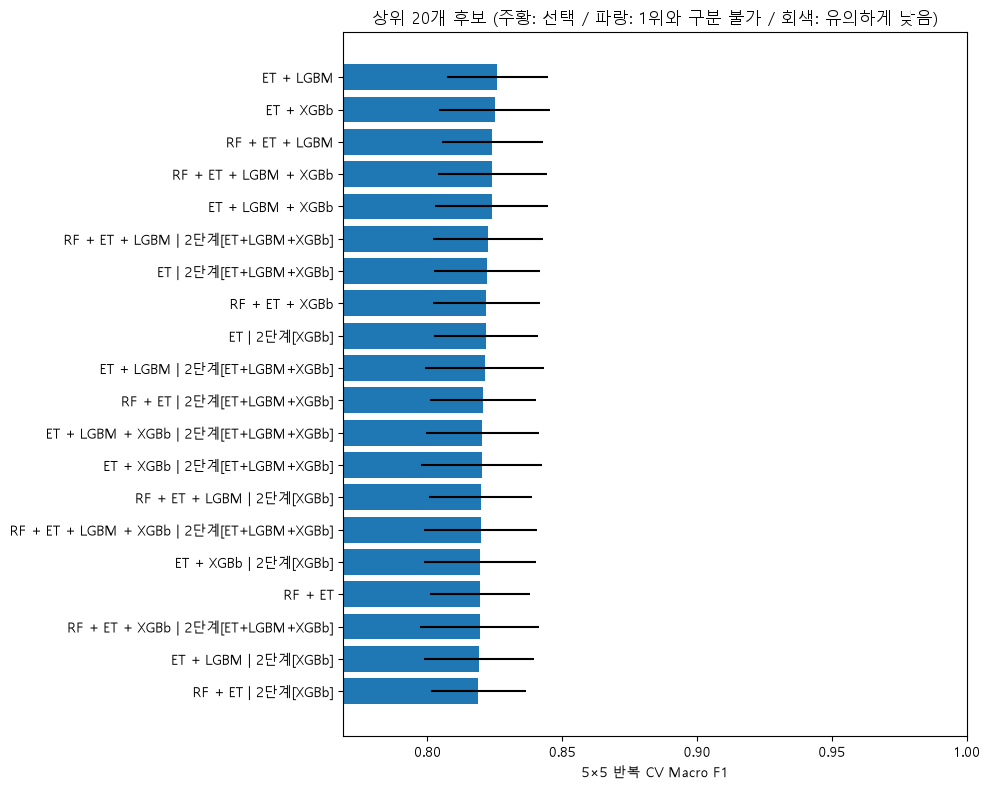

In [17]:
# ============================================================
# 15. 후보 조합 비교 + 통계적 모델 선택
# ============================================================
# 후보 = 1단계 (단일 6종 + 트리 4종 소프트 보팅 조합 11개)
#        × 2단계 (없음 / 전용 분류기 단일 3종 / 3종 평균)
# 모든 후보를 1위와 같은 25개 폴드에서 대응 비교 (보정 t검정).
# 1위와 유의한 차이가 없으면 "동급"으로 보고, PREFER_SIMPLER이면
# 동급 중 구성 모델 수가 가장 적은 후보를 선택한다.
# (0.01 수준의 차이로 복잡한 모델을 고르지 않기 위함)
# ============================================================

BASE_POOL = ["Random Forest", "ExtraTrees", "LightGBM", XGB_POOL]

base_options = [(m,) for m in model_makers]
for r in range(2, len(BASE_POOL) + 1):
    base_options += list(itertools.combinations(BASE_POOL, r))

spec_options = [()] + [(s,) for s in SPEC_POOL] + [tuple(SPEC_POOL)]


def candidate_proba(base_members, spec_members):
    p = np.mean([oof_base[m] for m in base_members], axis=0)
    if spec_members:
        p = mix_two_stage(p, np.mean([oof_spec[m] for m in spec_members], axis=0))
    return p


def candidate_name(base_members, spec_members):
    name = " + ".join(SHORT[m] for m in base_members)
    if spec_members:
        name += " | 2단계[" + "+".join(SHORT[m] for m in spec_members) + "]"
    return name


candidates = {}
for b in base_options:
    for s in spec_options:
        if b == ("Logistic Regression",) and s:
            continue
        pred = decide(candidate_proba(b, s))
        candidates[candidate_name(b, s)] = {
            "base": b, "spec": s, "pred": pred, "scores": fold_scores(pred),
        }

top_name = max(candidates, key=lambda k: candidates[k]["scores"].mean())
top_scores = candidates[top_name]["scores"]

pastry = class_mapping["Pastry"]
rows = []
for name, c in candidates.items():
    pcs = per_class_prf(c["pred"])
    d, l, h, p = corrected_ttest(c["scores"], top_scores) if name != top_name else (0, 0, 0, 1)
    rows.append({
        "Candidate": name,
        "Complexity": len(c["base"]) + len(c["spec"]),
        "CV Macro F1": c["scores"].mean(),
        "CV SD": c["scores"].std(),
        "Δ vs 1위": d, "CI low": l, "CI high": h, "p": p,
        "동급(1위와 구분 불가)": (name == top_name) or (h >= 0),
        "Pastry P": pcs.loc["Pastry", "precision"],
        "Pastry R": pcs.loc["Pastry", "recall"],
        "Bumps F1": pcs.loc["Bumps", "f1"],
        "Other F1": pcs.loc["Other_Faults", "f1"],
    })

candidate_df = (pd.DataFrame(rows)
                .sort_values("CV Macro F1", ascending=False)
                .reset_index(drop=True))

print(f"후보 수: {len(candidate_df)}  /  1위: {top_name} "
      f"({top_scores.mean():.4f} ± {top_scores.std():.4f})")
print(f"1위와 통계적으로 구분되지 않는 후보: {candidate_df['동급(1위와 구분 불가)'].sum()}개")
print("\n[상위 20개 후보]")
display(candidate_df.head(20).round(4))

if PREFER_SIMPLER:
    equiv = candidate_df[candidate_df["동급(1위와 구분 불가)"]]
    selected_name = equiv.sort_values(["Complexity", "CV Macro F1"],
                                      ascending=[True, False]).iloc[0]["Candidate"]
else:
    selected_name = top_name

selected = candidates[selected_name]
sel_row = candidate_df.set_index("Candidate").loc[selected_name]
print(f"\n→ 선택: {selected_name}  (CV {sel_row['CV Macro F1']:.4f} ± {sel_row['CV SD']:.4f}, "
      f"1위 대비 {sel_row['Δ vs 1위']:+.4f})")

# 2단계 모델 효과: 같은 1단계에서 2단계 유무 비교
print("\n[2단계 전용 분류기 효과 - 1단계 구성별 최고 2단계 vs 2단계 없음]")
two_stage_rows = []
for b in base_options:
    if b == ("Logistic Regression",):
        continue
    no_spec = candidates[candidate_name(b, ())]
    best_s = max(spec_options[1:],
                 key=lambda s: candidates[candidate_name(b, s)]["scores"].mean())
    with_spec = candidates[candidate_name(b, best_s)]
    d, l, h, p = corrected_ttest(with_spec["scores"], no_spec["scores"])
    p_no = per_class_prf(no_spec["pred"]).loc["Pastry", "precision"]
    p_with = per_class_prf(with_spec["pred"]).loc["Pastry", "precision"]
    two_stage_rows.append({
        "1단계": candidate_name(b, ()), "2단계": "+".join(SHORT[m] for m in best_s),
        "F1 없음": no_spec["scores"].mean(), "F1 2단계": with_spec["scores"].mean(),
        "Δ": d, "CI low": l, "CI high": h, "p": p,
        "Pastry P 없음": p_no, "Pastry P 2단계": p_with,
    })
two_stage_df = pd.DataFrame(two_stage_rows).sort_values("F1 2단계", ascending=False)
display(two_stage_df.round(4))

plot_df = candidate_df.head(20).iloc[::-1]
colors = ["tab:orange" if n == selected_name else
          ("tab:blue" if e else "tab:gray")
          for n, e in zip(plot_df["Candidate"], plot_df["동급(1위와 구분 불가)"])]
plt.figure(figsize=(10, 8))
plt.barh(plot_df["Candidate"], plot_df["CV Macro F1"], xerr=plot_df["CV SD"], color=colors)
plt.xlabel(f"{N_SPLITS}×{N_REPEATS} 반복 CV Macro F1")
plt.title("상위 20개 후보 (주황: 선택 / 파랑: 1위와 구분 불가 / 회색: 유의하게 낮음)")
plt.xlim(max(0, plot_df["CV Macro F1"].min() - 0.05), 1.0)
plt.tight_layout()
plt.show()

## 16. [개선 ①] 클래스별 결정 가중치 (임계값) 조정

In [18]:
# ============================================================
# 16. [개선 ①] 클래스별 결정 가중치 (임계값) 조정
# ============================================================
# 예측 = argmax(확률 × w). Bumps / Other_Faults / Pastry의 w만 조정
# (다른 4개 유형은 이미 잘 맞으므로 1로 고정 → 과적합 위험 축소).
#
# 같은 OOF로 가중치를 찾고 같은 OOF로 평가하면 낙관적이므로,
# 행을 5묶음으로 나눠 "4묶음으로 가중치 탐색 → 나머지 1묶음에 적용"하는
# 교차 적합(cross-fitting)으로 효과를 평가한다.
# ============================================================

WEIGHT_GRID = np.exp(np.linspace(-1.0, 1.0, 21))     # 약 0.37 ~ 2.72배


def fit_class_weights(proba, y, classes=GROUP, grid=WEIGHT_GRID, n_pass=3):
    """
    proba: (R, m, K) - 반복별 OOF 확률, y: (m,)
    좌표 상승법으로 반복 평균 Macro F1을 최대화하는 가중치 탐색
    """
    def objective(w):
        return np.mean([f1_score(y, decide(proba[r], w), average="macro", zero_division=0)
                        for r in range(proba.shape[0])])

    w = np.ones(proba.shape[-1])
    best = objective(w)
    for _ in range(n_pass):
        improved = False
        for k in classes:
            for g in grid:
                cand = w.copy()
                cand[k] = g
                s = objective(cand)
                if s > best + 1e-9:
                    best, w, improved = s, cand, True
        if not improved:
            break
    return w, best


sel_proba = candidate_proba(selected["base"], selected["spec"])     # (R, n, K)

# 교차 적합 평가
cf_pred = np.zeros((N_REPEATS, len(X_dev)), dtype=int)
cf_weights = []
row_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
for fit_idx, apply_idx in row_cv.split(X_dev, y_dev):
    w, _ = fit_class_weights(sel_proba[:, fit_idx], y_dev_np[fit_idx])
    cf_weights.append(w[GROUP])
    cf_pred[:, apply_idx] = decide(sel_proba[:, apply_idx], w)

s_noweight = selected["scores"]
s_crossfit = fold_scores(cf_pred)
d_w, lo_w, hi_w, p_w = corrected_ttest(s_crossfit, s_noweight)

print("=" * 60)
print(f"클래스별 결정 가중치 - 선택 모델: {selected_name}")
print("=" * 60)
print(f"가중치 없음          : {s_noweight.mean():.4f} ± {s_noweight.std():.4f}")
print(f"가중치 (교차 적합)   : {s_crossfit.mean():.4f} ± {s_crossfit.std():.4f}")
print(f"차이 = {d_w:+.4f}  95% CI [{lo_w:+.4f}, {hi_w:+.4f}]  p = {p_w:.3f}")
print("\n교차 적합 각 묶음에서 찾은 가중치 (" + " / ".join(CONFUSABLE) + "):")
for w in cf_weights:
    print("  ", np.round(w, 2))

# 최종 가중치: Dev 전체 OOF로 탐색
CLASS_WEIGHTS, _ = fit_class_weights(sel_proba, y_dev_np)
print("\n최종 가중치 (Dev 전체 OOF 기준):",
      {FAULT_COLS[k]: round(float(CLASS_WEIGHTS[k]), 3) for k in GROUP})

weight_cmp = pd.concat({
    "가중치 없음": per_class_prf(selected["pred"]),
    "가중치(교차적합)": per_class_prf(cf_pred),
}, axis=1).loc[CONFUSABLE]
print("\n[세 유형 precision / recall / F1 (OOF)]")
display(weight_cmp.round(4))

if CLASS_WEIGHT_POLICY == "auto":
    USE_CLASS_WEIGHTS = d_w > 0
elif CLASS_WEIGHT_POLICY == "on":
    USE_CLASS_WEIGHTS = True
else:
    USE_CLASS_WEIGHTS = False

print(f"\n→ 결정 가중치 적용: {USE_CLASS_WEIGHTS}"
      + ("" if p_w < ALPHA else "  (단, 효과가 통계적으로 확실하지는 않음)"))

클래스별 결정 가중치 - 선택 모델: XGB
가중치 없음          : 0.8180 ± 0.0195
가중치 (교차 적합)   : 0.8181 ± 0.0183
차이 = +0.0001  95% CI [-0.0104, +0.0106]  p = 0.982

교차 적합 각 묶음에서 찾은 가중치 (Bumps / Other_Faults / Pastry):
   [0.82 0.74 1.49]
   [1.11 0.82 1.65]
   [1.35 1.   2.01]
   [1.   1.   1.65]
   [1.11 0.82 1.65]

최종 가중치 (Dev 전체 OOF 기준): {'Bumps': 1.105, 'Other_Faults': 0.819, 'Pastry': 1.649}

[세 유형 precision / recall / F1 (OOF)]


가중치 없음                 가중치(교차적합)                
             precision  recall      f1 precision  recall      f1
Bumps           0.6859  0.6698  0.6776    0.6752  0.6941  0.6843
Other_Faults    0.7223  0.7918  0.7554    0.7410  0.7509  0.7458
Pastry          0.6941  0.5651  0.6228    0.6324  0.6397  0.6359


→ 결정 가중치 적용: True  (단, 효과가 통계적으로 확실하지는 않음)


## 17. 최종 모델 구성 함수 / 학습 → 검증 홀드아웃 확인

In [19]:
# ============================================================
# 17. 최종 모델 구성 함수 / 학습 → 검증 홀드아웃 확인
# ============================================================

def _vote(members):
    if len(members) == 1:
        return model_makers[members[0]]()
    return VotingClassifier(
        estimators=[(re.sub(r"\W+", "_", m), model_makers[m]()) for m in members],
        voting="soft", n_jobs=1,
    )


def build_estimator(base_members, spec_members=(), class_weights=None):
    est = _vote(base_members)
    if spec_members:
        est = TwoStageClassifier(base=est, specialist=_vote(spec_members), group=tuple(GROUP))
    if class_weights is not None:
        est = ClassWeightedClassifier(estimator=est, class_weights=class_weights)
    return est


def make_final_model():
    return build_estimator(
        selected["base"], selected["spec"],
        CLASS_WEIGHTS if USE_CLASS_WEIGHTS else None,
    )


# 홀드아웃은 CV 결과의 2차 점검용 (가중치는 Dev OOF로 정했으므로 제외)
holdout_names = list(dict.fromkeys(list(candidate_df["Candidate"].head(5)) + [selected_name]))
holdout_rows = []
for name in holdout_names:
    c = candidates[name]
    model = build_estimator(c["base"], c["spec"]).fit(X_train[FEATURES], y_train)
    holdout_rows.append({
        "Model": name,
        "CV Macro F1": c["scores"].mean(),
        "Val Macro F1": f1_score(y_val, model.predict(X_val[FEATURES]), average="macro"),
    })
holdout_df = pd.DataFrame(holdout_rows)
print("[반복 CV vs 학습→검증 홀드아웃]  (검증 388개 1회 점수는 변동이 큼)")
display(holdout_df.round(4))

[반복 CV vs 학습→검증 홀드아웃]  (검증 388개 1회 점수는 변동이 큼)


,Model,CV Macro F1,Val Macro F1
0,ET + LGBM,0.8259,0.7882
1,ET + XGBb,0.8249,0.8110
2,RF + ET + LGBM,0.8241,0.7897
3,RF + ET + LGBM + XGBb,0.8240,0.7922
4,ET + LGBM + XGBb,0.8238,0.7856
5,XGB,0.8180,0.7665


## 18. 테스트 평가 + 부트스트랩 신뢰구간 (마지막 1회)

최종 모델 학습 완료 (1.0초)
최종 테스트 결과 - XGB + 결정가중치
Accuracy: 0.8201
Balanced Acc: 0.8262
Precision: 0.8171
Recall: 0.8262
Macro F1: 0.8184

[테스트 점수 + 층화 부트스트랩 95% CI (B=2000)]


,Model,Test Macro F1,F1 CI low,F1 CI high,Pastry Precision,Pastry P CI,최종 - 이 모델,차이 CI low,차이 CI high,P(최종 ≤ 이 모델)
0,XGB + 결정가중치,0.8184,0.7688,0.8599,0.5682,"[0.462, 0.692]",0.0000,NaN,NaN,NaN
1,최종 (가중치 미적용),0.8144,0.7657,0.8564,0.6389,"[0.514, 0.778]",0.0040,-0.0102,0.0194,0.294
2,"v2 구성 (LGBM+XGB, 전체 변수)",0.8165,0.7705,0.8586,0.5854,"[0.475, 0.718]",0.0018,-0.0248,0.0219,0.436


→ '차이 CI'가 0을 포함하면 테스트 389개로는 두 모델의 차이를 확정할 수 없습니다.


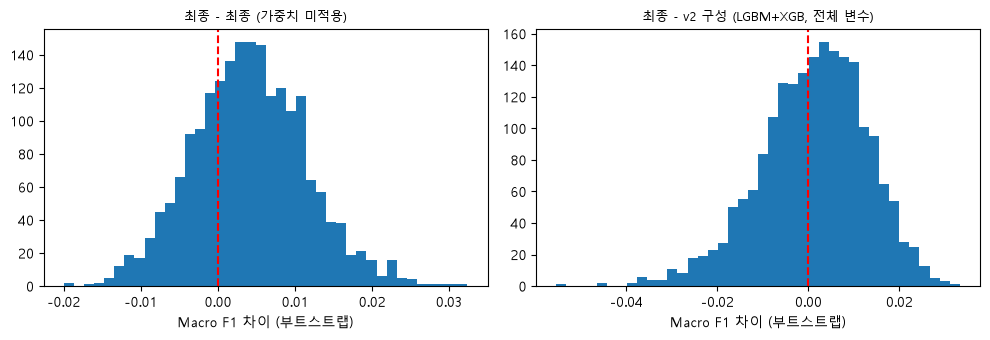

In [20]:
# ============================================================
# 18. 테스트 평가 + 부트스트랩 신뢰구간 (마지막 1회)
# ============================================================
# 비교 대상 (모두 학습+검증으로 학습):
#   - 최종 모델
#   - 최종 모델 (결정 가중치 미적용)        ← 가중치를 쓰는 경우
#   - CV 최고 단일 모델
#   - v2 최종 구성 (LGBM + 가중치 없는 XGB, 전체 변수)
# 층화 부트스트랩: 클래스별로 복원 추출해 소수 클래스가 빠지지 않게 한다.
# 같은 부트스트랩 표본에서 모델 간 차이를 계산 → 대응 차이 신뢰구간.
# ============================================================

start = time.time()
best_model = make_final_model().fit(X_dev[FEATURES], y_dev)
y_pred = best_model.predict(X_test[FEATURES])
test_scores = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Acc": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred, average="macro", zero_division=0),
}
final_label = selected_name + (" + 결정가중치" if USE_CLASS_WEIGHTS else "")
print(f"최종 모델 학습 완료 ({time.time() - start:.1f}초)")
print("=" * 60)
print(f"최종 테스트 결과 - {final_label}")
print("=" * 60)
for k, v in test_scores.items():
    print(f"{k}: {v:.4f}")

test_preds = {final_label: y_pred}

if USE_CLASS_WEIGHTS:
    test_preds["최종 (가중치 미적용)"] = decide(best_model.predict_proba(X_test[FEATURES]))

single_df = candidate_df[candidate_df["Complexity"] == 1]
best_single = single_df.iloc[0]["Candidate"]
if best_single != selected_name:
    m = build_estimator(candidates[best_single]["base"]).fit(X_dev[FEATURES], y_dev)
    test_preds[f"최고 단일: {best_single}"] = m.predict(X_test[FEATURES])

v2_model = VotingClassifier(
    estimators=[("lgbm", make_lgbm(TREES_FULL["lgbm"])), ("xgb", make_xgb(TREES_FULL["xgb"]))],
    voting="soft", n_jobs=1,
).fit(X_dev[FULL], y_dev)
test_preds["v2 구성 (LGBM+XGB, 전체 변수)"] = v2_model.predict(X_test[FULL])


rng = np.random.default_rng(RANDOM_STATE)
class_idx = [np.flatnonzero(y_test_np == k) for k in LABELS]
boot_f1 = {name: np.empty(N_BOOT) for name in test_preds}
boot_pastry_p = {name: np.empty(N_BOOT) for name in test_preds}

for b in range(N_BOOT):
    idx = np.concatenate([rng.choice(ix, size=len(ix), replace=True) for ix in class_idx])
    yt = y_test_np[idx]
    for name, pr in test_preds.items():
        boot_f1[name][b] = f1_score(yt, pr[idx], average="macro", zero_division=0)
        boot_pastry_p[name][b] = precision_score(
            yt, pr[idx], labels=[pastry], average="macro", zero_division=0)

q_lo, q_hi = 100 * ALPHA / 2, 100 * (1 - ALPHA / 2)
boot_rows = []
for name, pr in test_preds.items():
    diff_b = boot_f1[final_label] - boot_f1[name]
    boot_rows.append({
        "Model": name,
        "Test Macro F1": f1_score(y_test_np, pr, average="macro"),
        "F1 CI low": np.percentile(boot_f1[name], q_lo),
        "F1 CI high": np.percentile(boot_f1[name], q_hi),
        "Pastry Precision": precision_score(y_test_np, pr, labels=[pastry], average="macro", zero_division=0),
        "Pastry P CI": f"[{np.percentile(boot_pastry_p[name], q_lo):.3f}, "
                       f"{np.percentile(boot_pastry_p[name], q_hi):.3f}]",
        "최종 - 이 모델": f1_score(y_test_np, y_pred, average="macro") - f1_score(y_test_np, pr, average="macro"),
        "차이 CI low": np.percentile(diff_b, q_lo) if name != final_label else np.nan,
        "차이 CI high": np.percentile(diff_b, q_hi) if name != final_label else np.nan,
        "P(최종 ≤ 이 모델)": (diff_b <= 0).mean() if name != final_label else np.nan,
    })
boot_df = pd.DataFrame(boot_rows)
print(f"\n[테스트 점수 + 층화 부트스트랩 95% CI (B={N_BOOT})]")
display(boot_df.round(4))
print("→ '차이 CI'가 0을 포함하면 테스트 389개로는 두 모델의 차이를 확정할 수 없습니다.")

others = [n for n in test_preds if n != final_label]
if others:
    fig, axes = plt.subplots(1, len(others), figsize=(5 * len(others), 3.5), squeeze=False)
    for ax, name in zip(axes[0], others):
        d = boot_f1[final_label] - boot_f1[name]
        ax.hist(d, bins=40)
        ax.axvline(0, color="red", linestyle="--")
        ax.set_title(f"최종 - {name}", fontsize=9)
        ax.set_xlabel("Macro F1 차이 (부트스트랩)")
    plt.tight_layout()
    plt.show()

## 19. 결함 유형별 성능 / 세 유형 집중 비교 / 혼동행렬

              precision    recall  f1-score   support

      Pastry     0.5682    0.7812    0.6579        32
   Z_Scratch     0.9024    0.9737    0.9367        38
    K_Scatch     0.9870    0.9744    0.9806        78
      Stains     1.0000    0.9286    0.9630        14
   Dirtiness     0.7000    0.6364    0.6667        11
       Bumps     0.7407    0.7407    0.7407        81
Other_Faults     0.8211    0.7481    0.7829       135

    accuracy                         0.8201       389
   macro avg     0.8171    0.8262    0.8184       389
weighted avg     0.8278    0.8201    0.8217       389

[Bumps / Other_Faults / Pastry - 테스트 비교]


precision                       recall                           f1                     
Class                       Bumps Other_Faults  Pastry   Bumps Other_Faults  Pastry   Bumps Other_Faults  Pastry
Model                                                                                                           
XGB + 결정가중치                0.7407       0.8211  0.5682  0.7407       0.7481  0.7812  0.7407       0.7829  0.6579
v2 구성 (LGBM+XGB, 전체 변수)    0.7368       0.7812  0.5854  0.6914       0.7407  0.7500  0.7134       0.7605  0.6575
최종 (가중치 미적용)               0.7333       0.7664  0.6389  0.6790       0.7778  0.7188  0.7051       0.7721  0.6765

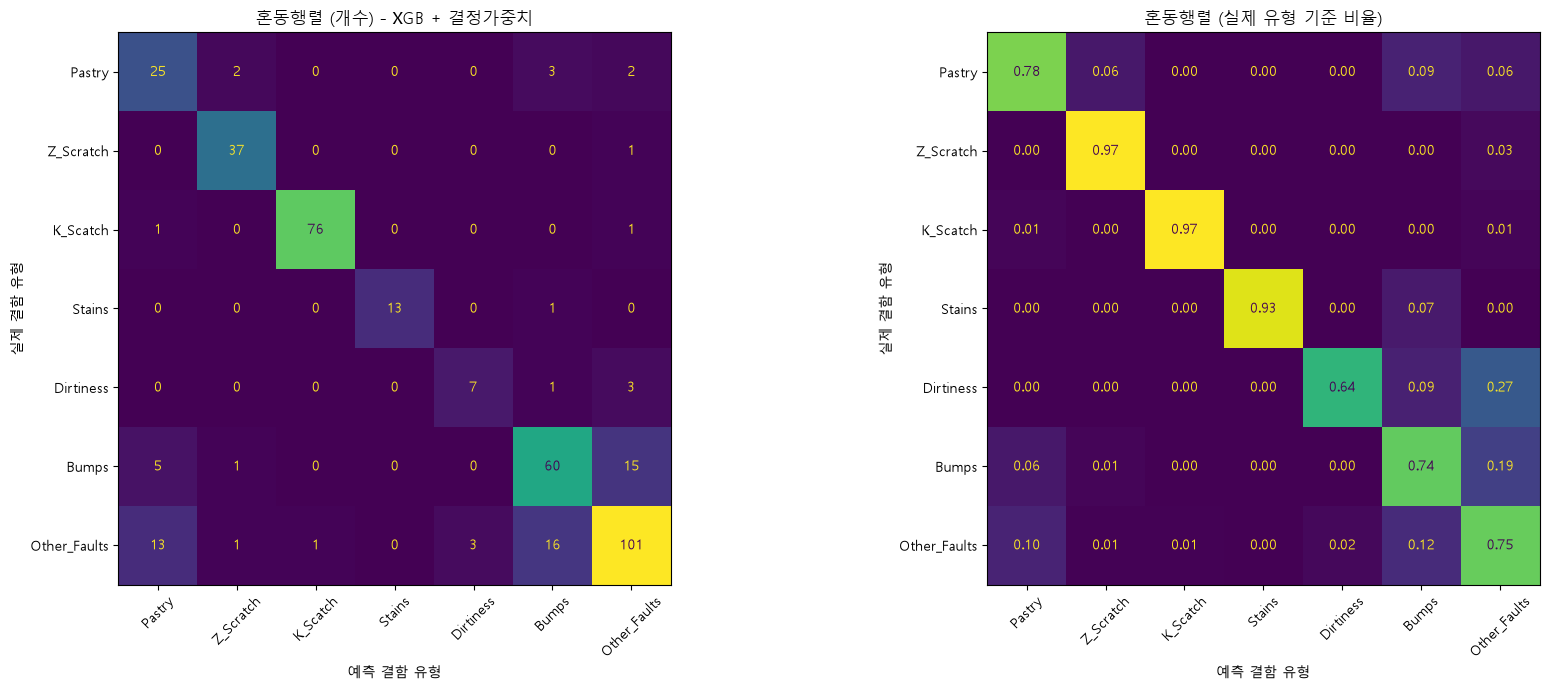

In [21]:
# ============================================================
# 19. 결함 유형별 성능 / 세 유형 집중 비교 / 혼동행렬
# ============================================================

print(classification_report(y_test, y_pred, labels=LABELS, target_names=FAULT_COLS,
                            digits=4, zero_division=0))

class_report_df = (
    pd.DataFrame(classification_report(
        y_test, y_pred, labels=LABELS, target_names=FAULT_COLS,
        output_dict=True, zero_division=0,
    )).T.loc[FAULT_COLS, ["precision", "recall", "f1-score", "support"]]
    .sort_values("f1-score")
)

focus_rows = []
for name, pr in test_preds.items():
    p_, r_, f_, _ = precision_recall_fscore_support(
        y_test_np, pr, labels=GROUP, zero_division=0)
    for cls, a, b_, c in zip(CONFUSABLE, p_, r_, f_):
        focus_rows.append({"Model": name, "Class": cls, "precision": a, "recall": b_, "f1": c})
focus_df = pd.DataFrame(focus_rows).pivot(index="Model", columns="Class")
print("[Bumps / Other_Faults / Pastry - 테스트 비교]")
display(focus_df.round(4))

cm = confusion_matrix(y_test, y_pred, labels=LABELS)
cm_norm = confusion_matrix(y_test, y_pred, labels=LABELS, normalize="true")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(cm, display_labels=FAULT_COLS).plot(ax=axes[0], xticks_rotation=45, colorbar=False)
axes[0].set_title(f"혼동행렬 (개수) - {final_label}")
ConfusionMatrixDisplay(cm_norm, display_labels=FAULT_COLS).plot(
    ax=axes[1], xticks_rotation=45, colorbar=False, values_format=".2f")
axes[1].set_title("혼동행렬 (실제 유형 기준 비율)")
for ax in axes:
    ax.set_xlabel("예측 결함 유형")
    ax.set_ylabel("실제 결함 유형")
plt.tight_layout()
plt.show()

## 20. 오분류 분석

In [22]:
# ============================================================
# 20. 오분류 분석
# ============================================================

test_proba = best_model.predict_proba(X_test[FEATURES])
test_result_df = pd.DataFrame({
    "Actual": y_test.map(reverse_class_mapping),
    "Predicted": pd.Series(y_pred, index=y_test.index).map(reverse_class_mapping),
    "Confidence": test_proba[np.arange(len(y_pred)), y_pred],
})
misclassified = test_result_df[test_result_df["Actual"] != test_result_df["Predicted"]]

print(f"오분류: {len(misclassified)} / {len(y_test)} ({len(misclassified) / len(y_test):.2%})")
misclassification_summary = (
    misclassified.groupby(["Actual", "Predicted"]).size()
    .reset_index(name="Count").sort_values("Count", ascending=False).reset_index(drop=True)
)
display(misclassification_summary.head(10))

in_group_err = misclassified.query("Actual in @CONFUSABLE and Predicted in @CONFUSABLE")
print(f"세 유형끼리의 오분류 비중: {len(in_group_err) / max(len(misclassified), 1):.1%}")

misclassified_rows = df.loc[misclassified.index].join(misclassified[["Predicted", "Confidence"]])

오분류: 70 / 389 (17.99%)


,Actual,Predicted,Count
0,Other_Faults,Bumps,16
1,Bumps,Other_Faults,15
2,Other_Faults,Pastry,13
3,Bumps,Pastry,5
4,Other_Faults,Dirtiness,3
5,Pastry,Bumps,3
6,Dirtiness,Other_Faults,3
7,Pastry,Other_Faults,2
8,Pastry,Z_Scratch,2
9,K_Scatch,Other_Faults,1


세 유형끼리의 오분류 비중: 77.1%


## 21. 변수 중요도 (Permutation Importance, 테스트)

Permutation Importance 계산 중...


,Rank,Feature,Importance Mean,Importance SD
0,1,Thick_x_Steel,0.0880,0.0112
1,2,Length_of_Conveyer,0.0863,0.0118
2,3,Steel_Plate_Thickness,0.0266,0.0064
3,4,Y_Minimum,0.0240,0.0104
4,5,X_Minimum,0.0212,0.0078
5,6,Edges_Y_Index,0.0167,0.0093
6,7,Luminosity_Range,0.0140,0.0053
7,8,Minimum_of_Luminosity,0.0133,0.0063
8,9,Edges_Index,0.0131,0.0035
9,10,Orientation_Index,0.0088,0.0128


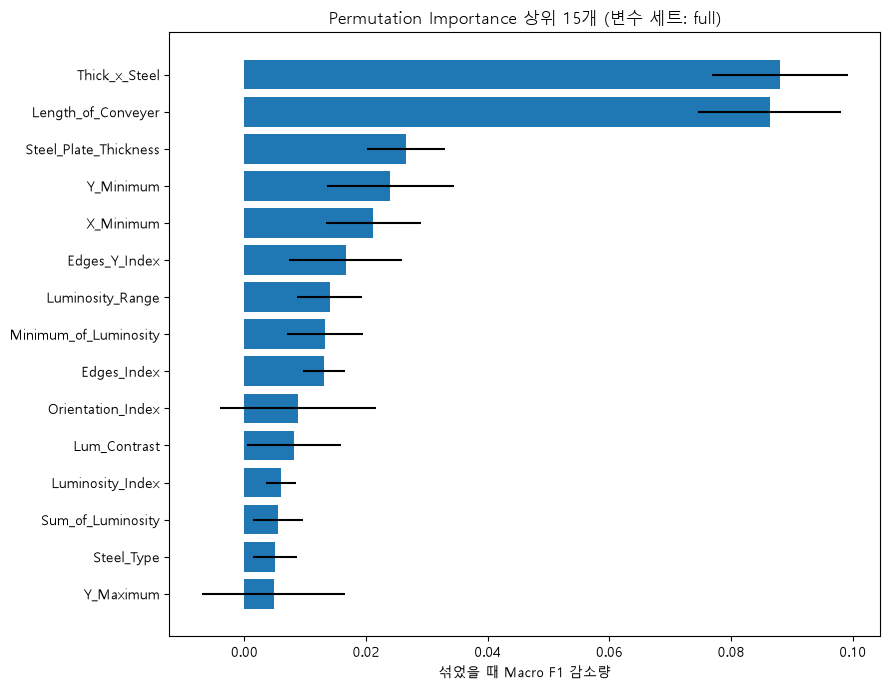

In [23]:
# ============================================================
# 21. 변수 중요도 (Permutation Importance, 테스트)
# ============================================================

print("Permutation Importance 계산 중...")
perm = permutation_importance(
    best_model, X_test[FEATURES], y_test, scoring="f1_macro",
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=1,
)
importance_df = (
    pd.DataFrame({"Feature": FEATURES,
                  "Importance Mean": perm.importances_mean,
                  "Importance SD": perm.importances_std})
    .sort_values("Importance Mean", ascending=False).reset_index(drop=True)
)
importance_df.insert(0, "Rank", range(1, len(importance_df) + 1))
display(importance_df.head(20).round(4))

plot_df = importance_df.head(15).iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(plot_df["Feature"], plot_df["Importance Mean"], xerr=plot_df["Importance SD"])
plt.xlabel("섞었을 때 Macro F1 감소량")
plt.title(f"Permutation Importance 상위 15개 (변수 세트: {FEATURE_SET_NAME})")
plt.tight_layout()
plt.show()

## 22. 최종 분석 요약

In [24]:
# ============================================================
# 22. 최종 분석 요약
# ============================================================

final_boot = boot_df.set_index("Model").loc[final_label]
print("=" * 60)
print("최종 분석 요약 (v3)")
print("=" * 60)
print(f"분할: 학습 {len(X_train)} / 검증 {len(X_val)} / 테스트 {len(X_test)}")
print(f"평가 방식: {N_SPLITS}×{N_REPEATS} 반복 층화 CV + 보정 t검정, 테스트 부트스트랩 B={N_BOOT}")
print(f"\n[XGB 가중치] balanced - 없음 = {xgb_diff:+.4f} [{xgb_lo:+.4f}, {xgb_hi:+.4f}] → 사용: {XGB_POOL}")
for fs in ["drop_basic", "drop_strict"]:
    r = ens_res.loc[fs]
    print(f"[변수 제거] {fs:<12} Δ = {r['Δ vs full']:+.4f} [{r['CI low']:+.4f}, {r['CI high']:+.4f}]")
print(f"→ 사용 변수 세트: {FEATURE_SET_NAME} ({len(FEATURES)}개)")
print(f"\n[모델 선택] CV 1위: {top_name} ({top_scores.mean():.4f})")
print(f"            선택  : {selected_name} ({sel_row['CV Macro F1']:.4f}), "
      f"1위와 구분 불가 후보 {candidate_df['동급(1위와 구분 불가)'].sum()}개")
print(f"[결정 가중치] 교차 적합 Δ = {d_w:+.4f} [{lo_w:+.4f}, {hi_w:+.4f}] → 적용: {USE_CLASS_WEIGHTS}")
print(f"\n최종 모델: {final_label}")
print(f"테스트 Macro F1: {test_scores['Macro F1']:.4f} "
      f"(95% CI {final_boot['F1 CI low']:.4f} ~ {final_boot['F1 CI high']:.4f})")
print(f"테스트 Accuracy: {test_scores['Accuracy']:.4f}")
print(f"Pastry Precision: {final_boot['Pastry Precision']:.4f} {final_boot['Pastry P CI']}")
print("가장 어려운 결함 유형:", class_report_df.index[0],
      f"(F1 {class_report_df['f1-score'].iloc[0]:.3f})")
print("중요 변수 Top 5:", importance_df["Feature"].head(5).tolist())

최종 분석 요약 (v3)
분할: 학습 1164 / 검증 388 / 테스트 389
평가 방식: 5×5 반복 층화 CV + 보정 t검정, 테스트 부트스트랩 B=2000

[XGB 가중치] balanced - 없음 = -0.0056 [-0.0241, +0.0130] → 사용: XGBoost (balanced)
[변수 제거] drop_basic   Δ = -0.0180 [-0.0311, -0.0049]
[변수 제거] drop_strict  Δ = -0.0297 [-0.0491, -0.0103]
→ 사용 변수 세트: full (38개)

[모델 선택] CV 1위: ET + LGBM (0.8259)
            선택  : XGB (0.8180), 1위와 구분 불가 후보 70개
[결정 가중치] 교차 적합 Δ = +0.0001 [-0.0104, +0.0106] → 적용: True

최종 모델: XGB + 결정가중치
테스트 Macro F1: 0.8184 (95% CI 0.7688 ~ 0.8599)
테스트 Accuracy: 0.8201
Pastry Precision: 0.5682 [0.462, 0.692]
가장 어려운 결함 유형: Pastry (F1 0.658)
중요 변수 Top 5: ['Thick_x_Steel', 'Length_of_Conveyer', 'Steel_Plate_Thickness', 'Y_Minimum', 'X_Minimum']


## 23. 전체 데이터로 재학습 및 저장

In [25]:
# ============================================================
# 23. 전체 데이터로 재학습 및 저장
# ============================================================
# 주의: BalancedXGBClassifier / TwoStageClassifier / ClassWeightedClassifier는
# 이 노트북에서 정의한 클래스이므로, 다른 환경에서 불러올 때는
# 같은 클래스 정의를 먼저 실행(또는 모듈로 import)해야 한다.
# ============================================================

final_model = make_final_model().fit(X_all[FEATURES], y_all)

joblib.dump(
    {
        "model": final_model,
        "model_name": final_label,
        "base_members": list(selected["base"]),
        "specialist_members": list(selected["spec"]),
        "class_weights": CLASS_WEIGHTS.tolist() if USE_CLASS_WEIGHTS else None,
        "feature_set": FEATURE_SET_NAME,
        "feature_cols": FEATURES,
        "class_names": FAULT_COLS,
    },
    "steel_fault_model_v3.joblib",
)
print("최종 모델 저장 완료: steel_fault_model_v3.joblib")

최종 모델 저장 완료: steel_fault_model_v3.joblib


## 24. 새로운 데이터 예측 함수

In [26]:
# ============================================================
# 24. 새로운 데이터 예측 함수
# ============================================================

def predict_faults(new_data: pd.DataFrame,
                   model_path: str = "steel_fault_model_v3.joblib") -> pd.DataFrame:

    bundle = joblib.load(model_path)
    model, names = bundle["model"], bundle["class_names"]

    merged = merge_columns(new_data.drop(columns=names, errors="ignore"))
    X_new = build_features(merged)[bundle["feature_cols"]]

    proba = model.predict_proba(X_new)
    pred = np.asarray(model.predict(X_new))          # 결정 가중치 반영

    output = pd.DataFrame(proba, columns=[f"prob_{n}" for n in names], index=new_data.index)
    output.insert(0, "predicted_fault", [names[i] for i in pred])
    output.insert(1, "confidence", proba[np.arange(len(pred)), pred])
    return output


demo = predict_faults(raw_df.loc[X_test.index[:5]])
demo.insert(0, "actual_fault", df.loc[X_test.index[:5], TARGET].values)
print("[예측 함수 동작 확인] (전체 데이터로 학습한 모델이므로 성능 확인용 아님)")
display(demo.round(3))

[예측 함수 동작 확인] (전체 데이터로 학습한 모델이므로 성능 확인용 아님)


,actual_fault,predicted_fault,confidence,prob_Pastry,prob_Z_Scratch,prob_K_Scatch,prob_Stains,prob_Dirtiness,prob_Bumps,prob_Other_Faults
904,Bumps,Bumps,0.981,0.001,0.000,0.001,0.000,0.000,0.981,0.017
492,K_Scatch,K_Scatch,0.999,0.000,0.000,0.999,0.000,0.000,0.000,0.001
232,Z_Scratch,Z_Scratch,0.981,0.000,0.981,0.000,0.000,0.000,0.001,0.017
1093,Bumps,Bumps,0.829,0.008,0.003,0.005,0.001,0.001,0.829,0.154
803,Stains,Stains,0.994,0.000,0.001,0.000,0.994,0.000,0.001,0.003


## 25. 결과 파일 저장